<a href="https://colab.research.google.com/github/tedteske/bounded_lognorm/blob/master/notebooks/Applications_100m_Sprints.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# What are the fastest possible 100m sprint times?

The idea: fit a *bounded* distribution to Olympic sprint speeds and read the fitted upper bound as the speed of the best possible runner.

*Original analysis: Ted Teske (2020), with the notebook-era bounded lognormal. Revised in November 2026 (Phase 6; Ted Teske with Claude, Anthropic) to run on the [`bounded-lognorm`](https://pypi.org/project/bounded-lognorm/) package, on both of its distributions, with a bootstrap in place of the least-squares covariance. What changed, and why, is summarized at the end and in [`docs/phase6_use_cases.md`](https://github.com/tedteske/bounded_lognorm/blob/master/docs/phase6_use_cases.md).*

Runs top to bottom in Google Colab in about 10 minutes, most of it bootstrap refits.

In [1]:
%pip install -q bounded-lognorm==0.2.1

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy import stats

import bounded_lognorm
from bounded_lognorm import bl, bl2

print('bounded-lognorm', bounded_lognorm.__version__, '| numpy', np.__version__,
      '| scipy', scipy.__version__, '| pandas', pd.__version__)

# The two families. They are different distributions (next section), so every
# number below is printed with its family's name, and every plot draws BL as a
# solid blue line and BL2 as a dashed orange one.
FAMILIES = {'BL': bl, 'BL2': bl2}
STYLE = {'BL': dict(color='#2a78d6', ls='-', lw=2),
         'BL2': dict(color='#eb6834', ls='--', lw=2)}
INK, GRID, BARS = '#3b3a36', '#e4e2db', '#c9c7be'
plt.rcParams.update({'figure.figsize': (10, 10 / 1.6), 'font.family': 'serif',
                     'axes.edgecolor': GRID, 'axes.labelcolor': INK,
                     'xtick.color': INK, 'ytick.color': INK,
                     'axes.grid': True, 'grid.color': GRID,
                     'axes.spines.top': False, 'axes.spines.right': False})

# Bootstrap sizes. Set BOOTSTRAP_B in the environment for a quicker run
# (BL2 fits are slower, so BL2 gets half as many resamples).
B = {'BL': int(os.environ.get('BOOTSTRAP_B', 400))}
B['BL2'] = max(B['BL'] // 2, 2)
REPEATS = int(os.environ.get('REPEATS', 100))     # repeated samples, last part


def fit(family, data, method='LSQ', **kw):
    """fit_bounds for one family. A fit the data cannot support comes back
    with success=False and the reason in .message; the warning it raises is
    recorded rather than printed, and shown by report()."""
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', RuntimeWarning)
        f = FAMILIES[family].fit_bounds(data, method, **kw)
    f.family = family
    f.ecdf = kw.get('ecdf', 'midpoint') if method == 'LSQ' else None
    return f


def label(f):
    ecdf = f" ({f.ecdf} ECDF)" if f.method == 'LSQ' else ''
    return f"{f.family:<3} {f.method}{ecdf}"


def report(f, time_unit=True):
    """One line per fit, always naming the family."""
    line = (f"{label(f):<24} mode {f.mode:.3f}  sigma {f.sigma:.3f}  "
            f"lower {f.lower:.3f}  upper {f.upper:.3f}")
    if time_unit:
        line += f"  ->  best possible time {100 / f.upper:.2f} s"
    line += f"  (neg. log-likelihood {f.nnlf:.1f})"
    if not f.success:
        line += f"\n{'':<24} NOT IDENTIFIED: {f.message.split(':')[0]}"
    print(line)

bounded-lognorm 0.2.1 | numpy 2.5.4 | scipy 1.18.1 | pandas 3.1.0


## Two distributions, not one

The package has two bounded lognormals with the same parameters (mode, sigma, lower bound, upper bound) and the same API:

- **BL** (`bl`) is the original piecewise form, the one this notebook used in 2020.
- **BL2** (`bl2`) is a smooth form, built later.

They are **different distributions**. With the same four parameters their CDFs differ, as below, so a number from one never stands in for the other. Below, each family is fitted to the same data separately, and every result says which family it came from.

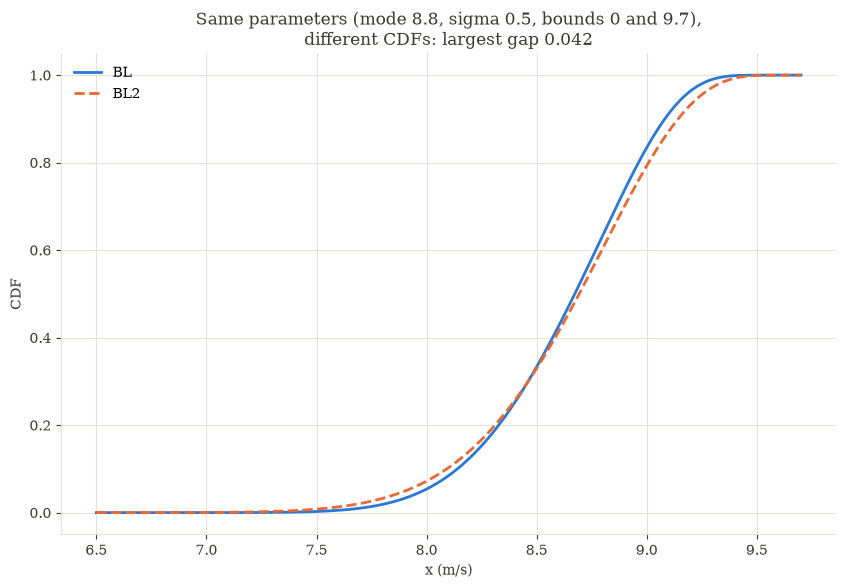

In [3]:
params = dict(mode=8.8, sigma=0.5, lower=0, upper=9.7)   # sprint-like, in m/s
x = np.linspace(6.5, 9.7, 801)
fig, ax = plt.subplots()
for fam, dist in FAMILIES.items():
    ax.plot(x, dist.from_bounds(**params).cdf(x), label=fam, **STYLE[fam])
gap = np.max(np.abs(bl.from_bounds(**params).cdf(x) - bl2.from_bounds(**params).cdf(x)))
ax.set_title(f'Same parameters (mode 8.8, sigma 0.5, bounds 0 and 9.7),\n'
             f'different CDFs: largest gap {gap:.3f}', color=INK)
ax.set_xlabel('x (m/s)'); ax.set_ylabel('CDF')
ax.legend(frameon=False)
plt.show()

## The data

Results from every heat of the 2004–2016 Olympics. See [here](https://doi.org/10.7302/Z20V8B11) for details on this dataset (Mirshams Shahshahani 2018, CC0). A copy is kept in the repository, so the notebook reads that first and falls back to the original download link.

In [4]:
SOURCES = ['data/2004-2016-Short-Races.csv',     # running from the repo checkout
           'https://raw.githubusercontent.com/tedteske/bounded_lognorm/master/'
           'notebooks/data/2004-2016-Short-Races.csv',
           'https://deepblue.lib.umich.edu/data/downloads/qn59q4716?locale=en']
for src in SOURCES:
    try:
        sprint_data = pd.read_csv(src, encoding='ISO-8859-1')
        print('read', src)
        break
    except Exception as e:                       # missing file or no network
        print('could not read', src, '-', type(e).__name__)
sprint_data.head()

read data/2004-2016-Short-Races.csv


,POS,BIB,ATHLETE,COUNTRY,MARK,RxnTime,Race,Round,Gender,Year
0,1.0,NaN,Usain BOLT,JAMJAM,10.20 Q,0.186,100 m,Heats,M,2008
1,2.0,NaN,Daniel BAILEY,ANTANT,10.24 Q,0.198,100 m,Heats,M,2008
2,3.0,NaN,Vicente DE LIMA,BRABRA,10.26 Q,0.168,100 m,Heats,M,2008
3,4.0,NaN,Henry VIZCAÍNO,CUBCUB,10.28 q,0.157,100 m,Heats,M,2008
4,5.0,NaN,Fabio CERUTTI,ITAITA,10.49,0.136,100 m,Heats,M,2008


Isolate the 100m sprint times, clean up the `MARK` field (time in seconds), and convert to average speed (meters per second).

In [5]:
sprint_data = sprint_data[sprint_data.Race == '100 m'].copy()
sprint_data['speed'] = pd.to_numeric(sprint_data.MARK.str.split(expand=True)[0],
                                     errors='coerce')
sprint_data = sprint_data[sprint_data['speed'] > 0]
sprint_data['speed'] = 100 / sprint_data['speed']

speeds_M = sprint_data[sprint_data.Gender == 'M']['speed'].to_numpy()
speeds_W = sprint_data[sprint_data.Gender == 'F']['speed'].to_numpy()
mode_W = pd.Series(speeds_W).mode()[0]     # the original fixes the women's mode here

for name, s in (('men', speeds_M), ('women', speeds_W)):
    print(f"{name:<5}: {s.size} runs, {np.unique(s).size} distinct times, "
          f"fastest {100 / s.max():.2f} s, slowest {100 / s.min():.2f} s")
print(f"women's most frequent speed: {mode_W:.3f} m/s")

men  : 781 runs, 172 distinct times, fastest 9.63 s, slowest 50.94 s
women: 691 runs, 216 distinct times, fastest 10.71 s, slowest 14.82 s
women's most frequent speed: 8.834 m/s


## 1. Reproducing the original analysis

The original fit was least squares on the empirical CDF with the lower bound fixed at 0: `bounded_lognorm.fit(speeds, MLE=False, flower=0)`, with `fmode` added for the women. In the package that is `bl.fit_bounds(speeds, 'LSQ', flower=0)`. Adding `ecdf='step'` reproduces the original's empirical CDF exactly (`i/n`; the package's default is the midpoint, `(i - 1/2)/n`).

**Women** first, where the original's numbers come back exactly: an upper bound of 9.674 m/s, a best possible time of **10.34 s**, and the original's interval of **[10.25, 10.43] s** from the least-squares covariance (±2 standard errors).

In [6]:
f = fit('BL', speeds_W, 'LSQ', flower=0, fmode=mode_W, ecdf='step')
report(f)
se = f.stderr.upper
print(f"BL  covariance interval (+-2 SE, as the original): "
      f"[{100 / (f.upper + 2 * se):.2f}, {100 / (f.upper - 2 * se):.2f}] s")

BL  LSQ (step ECDF)      mode 8.834  sigma 0.510  lower 0.000  upper 9.674  ->  best possible time 10.34 s  (neg. log-likelihood 459.5)
BL  covariance interval (+-2 SE, as the original): [10.25, 10.43] s


**Men.** The original reported 9.44 s. The same fit in the package does not: the least-squares fit improves all the way as the upper bound approaches the fastest speed in the data, Usain Bolt's 9.63 s at London 2012, and stops there. Since 0.2.1 the package reports this as a failure to identify the bound instead of returning it as an estimate.

In [7]:
f = fit('BL', speeds_M, 'LSQ', flower=0, ecdf='step')
report(f)
print(f"fastest run in the data: {100 / speeds_M.max():.2f} s; "
      f"fitted bound minus fastest speed: {f.upper - speeds_M.max():.1e} m/s")

BL  LSQ (step ECDF)      mode 9.793  sigma 0.450  lower 0.000  upper 10.384  ->  best possible time 9.63 s  (neg. log-likelihood 1978.5)
                         NOT IDENTIFIED: upper collapsed onto max(data)
fastest run in the data: 9.63 s; fitted bound minus fastest speed: 4.7e-10 m/s


So where did 9.44 s come from? The original's fitted parameters were mode 9.7526, sigma 0.3157 and upper bound 10.593 m/s (100/10.593 = 9.44 s). That point is not a least-squares optimum. Below, the squared error at that point is compared with a refit holding the upper bound at the same 10.593 and with the free fit. (BL's CDF in the package agrees with the original code's to 1e-14 at that point, checked in Phase 6 with the original code kept in `tests/bl_original.py`; so the comparison is like for like.)

In [8]:
x_e, n_e = np.unique(speeds_M, return_counts=True)
F_e = np.cumsum(n_e) / speeds_M.size                     # the original's step ECDF

def ssr(mode, sigma, lower, upper):
    r = bl.from_bounds(mode, sigma, lower, upper).cdf(x_e) - F_e
    return r @ r

original = (9.7526, 0.3157, 0, 10.593)
held = fit('BL', speeds_M, 'LSQ', flower=0, fupper=10.593, ecdf='step')
free = fit('BL', speeds_M, 'LSQ', flower=0, ecdf='step')
print(f"BL  squared error at the original's parameters (9.44 s):    {ssr(*original):.3f}")
print(f"BL  best fit with the upper bound held at 10.593 (9.44 s): {ssr(*held):.3f}")
print(f"BL  best fit, upper bound free (collapses onto 9.63 s):    {ssr(*free):.3f}")

BL  squared error at the original's parameters (9.44 s):    0.599
BL  best fit with the upper bound held at 10.593 (9.44 s): 0.198
BL  best fit, upper bound free (collapses onto 9.63 s):    0.166


The original's point is three times worse than the best fit with the same upper bound, and the free fit is better still, at the record. The optimizer stopped early in 2020. Run today (SciPy 1.18) from the original's default starting point, the original code stops somewhere else again (mode = upper bound = 10.03 m/s, below the fastest run, which is not a valid fit). The 9.44 s was where the optimizer happened to stop, not something the data say.

## 2. What changes with the ECDF convention, MLE, and BL2

Each family fitted separately to the same data, by least squares with each ECDF convention and by maximum likelihood (MLE), with the lower bound fixed at 0 throughout and the women's mode fixed as in the original.

In [9]:
fits = {}
for who, data, kw in (('men', speeds_M, dict(flower=0)),
                      ('women', speeds_W, dict(flower=0, fmode=mode_W))):
    print(f"--- {who}")
    for fam in FAMILIES:
        for method, ecdf in (('LSQ', 'step'), ('LSQ', 'midpoint'), ('MLE', None)):
            f = fit(fam, data, method, **kw, **({'ecdf': ecdf} if ecdf else {}))
            fits[who, fam, method, ecdf] = f
            report(f)

--- men


BL  LSQ (step ECDF)      mode 9.793  sigma 0.450  lower 0.000  upper 10.384  ->  best possible time 9.63 s  (neg. log-likelihood 1978.5)
                         NOT IDENTIFIED: upper collapsed onto max(data)


BL  LSQ (midpoint ECDF)  mode 9.799  sigma 0.452  lower 0.000  upper 10.384  ->  best possible time 9.63 s  (neg. log-likelihood 2007.8)
                         NOT IDENTIFIED: upper collapsed onto max(data)


BL  MLE                  mode 9.926  sigma 0.982  lower 0.000  upper 10.409  ->  best possible time 9.61 s  (neg. log-likelihood 579.3)


BL2 LSQ (step ECDF)      mode 9.744  sigma 0.397  lower 0.000  upper 10.384  ->  best possible time 9.63 s  (neg. log-likelihood 1189.3)
                         NOT IDENTIFIED: upper collapsed onto max(data)


BL2 LSQ (midpoint ECDF)  mode 9.750  sigma 0.398  lower 0.000  upper 10.384  ->  best possible time 9.63 s  (neg. log-likelihood 1231.5)
                         NOT IDENTIFIED: upper collapsed onto max(data)


BL2 MLE                  mode 9.839  sigma 0.810  lower 0.000  upper 10.398  ->  best possible time 9.62 s  (neg. log-likelihood 489.6)
--- women
BL  LSQ (step ECDF)      mode 8.834  sigma 0.510  lower 0.000  upper 9.674  ->  best possible time 10.34 s  (neg. log-likelihood 459.5)
BL  LSQ (midpoint ECDF)  mode 8.834  sigma 0.507  lower 0.000  upper 9.697  ->  best possible time 10.31 s  (neg. log-likelihood 463.3)
BL  MLE                  mode 8.834  sigma 0.708  lower 0.000  upper 9.465  ->  best possible time 10.57 s  (neg. log-likelihood 384.9)
BL2 LSQ (step ECDF)      mode 8.834  sigma 0.489  lower 0.000  upper 9.441  ->  best possible time 10.59 s  (neg. log-likelihood 391.4)


BL2 LSQ (midpoint ECDF)  mode 8.834  sigma 0.486  lower 0.000  upper 9.459  ->  best possible time 10.57 s  (neg. log-likelihood 394.8)


BL2 MLE                  mode 8.834  sigma 0.643  lower 0.000  upper 9.373  ->  best possible time 10.67 s  (neg. log-likelihood 356.8)


For the men, every least-squares fit, in both families and with both ECDFs, collapses onto the record (9.63 s), and MLE puts the bound just past it (9.61–9.62 s).

How well does each fit describe the data? The Kolmogorov–Smirnov distance (the largest gap between the fitted and empirical CDFs) answers that directly:

In [10]:
data_of = {'men': speeds_M, 'women': speeds_W}
for (who, fam, method, ecdf), f in fits.items():
    ks = stats.kstest(data_of[who], FAMILIES[fam].from_bounds(*f).cdf).statistic
    print(f"{who:<5}  {label(f):<24} KS distance {ks:.3f}")
print(f"slowest runs (s): men {np.round(np.sort(100 / speeds_M)[-3:], 2)}, "
      f"women {np.round(np.sort(100 / speeds_W)[-3:], 2)}")

men    BL  LSQ (step ECDF)      KS distance 0.072
men    BL  LSQ (midpoint ECDF)  KS distance 0.066
men    BL  MLE                  KS distance 0.227
men    BL2 LSQ (step ECDF)      KS distance 0.070
men    BL2 LSQ (midpoint ECDF)  KS distance 0.064
men    BL2 MLE                  KS distance 0.172
women  BL  LSQ (step ECDF)      KS distance 0.087
women  BL  LSQ (midpoint ECDF)  KS distance 0.085
women  BL  MLE                  KS distance 0.206
women  BL2 LSQ (step ECDF)      KS distance 0.082
women  BL2 LSQ (midpoint ECDF)  KS distance 0.079
women  BL2 MLE                  KS distance 0.159
slowest runs (s): men [16.4  22.69 50.94], women [14.7  14.8  14.82]


Least squares follows the data reasonably (KS distance 0.06–0.09); maximum likelihood does not (0.16–0.23). With the lower bound fixed at 0, the likelihood has to account for every run, including a few very slow ones (the slowest men's run took 50.94 s, an average of 1.96 m/s), with a single sigma below the mode, and it widens the whole distribution to do so. That puts the MLE estimates of the bound on fits that describe the fast end poorly, so they deserve less weight than the least-squares ones. The original's choice of least squares was a reasonable one for these data.

For the women:

- the ECDF convention moves the estimate by 0.02–0.03 s;
- the family moves it by 0.25 s under least squares (10.34 s for BL against 10.59 s for BL2, step ECDF) and by 0.10 s under MLE;
- MLE instead of least squares moves BL's estimate by 0.23 s and BL2's by 0.08 s.

By likelihood, BL2 beats BL on both data sets with the same number of parameters (the negative log-likelihood is lower by about 90 for the men and 28 for the women), though neither MLE fit is good. Under least squares the two families fit about equally well (below). Where they differ most is how far beyond the data they extrapolate, and the extrapolation is the whole answer here.

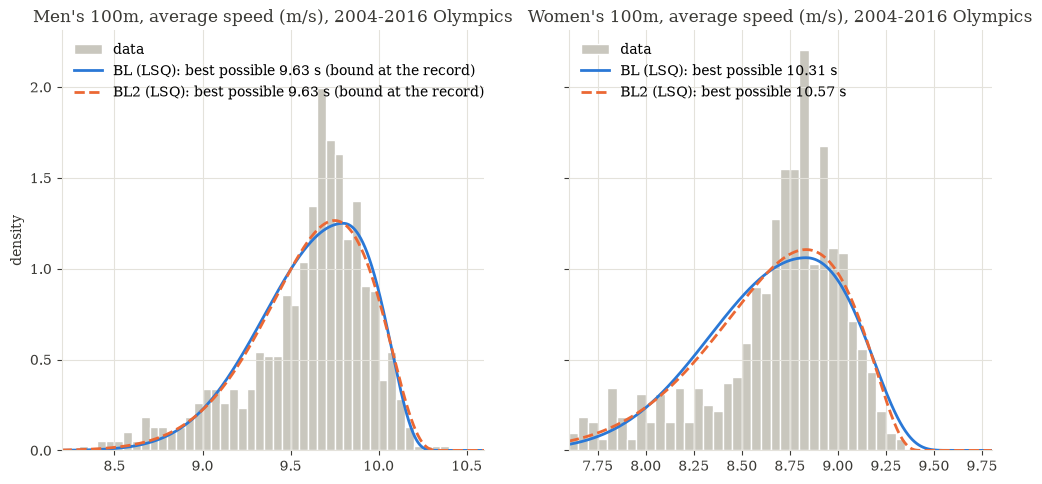

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 12 / 2.2), sharey=True)
for ax, (who, data, xlim) in zip(axes, (('men', speeds_M, (8.2, 10.6)),
                                        ('women', speeds_W, (7.6, 9.8)))):
    bins = np.arange(xlim[0], xlim[1] + 0.05, 0.05)
    ax.hist(data, bins=bins, density=True, color=BARS, edgecolor='white', lw=1,
            label='data')
    x = np.linspace(*xlim, 801)
    for fam in FAMILIES:
        f = fits[who, fam, 'LSQ', 'midpoint']
        note = '' if f.success else ' (bound at the record)'
        ax.plot(x, FAMILIES[fam].from_bounds(*f).pdf(x), **STYLE[fam],
                label=f"{fam} (LSQ): best possible {100 / f.upper:.2f} s{note}")
    ax.set_title(f"{who.capitalize()}'s 100m, average speed (m/s), 2004-2016 Olympics",
                 color=INK)
    ax.set_xlim(xlim); ax.legend(frameon=False, loc='upper left')
axes[0].set_ylabel('density')
plt.show()

## 3. Uncertainty: a bootstrap instead of the covariance

The original's interval came from the least-squares covariance. That covariance treats the residuals between the fitted and empirical CDFs as independent, which they are not (each ECDF point contains all the points below it), so it understates the uncertainty. Part 4 measures by how much. The honest alternative is to refit many bootstrap resamples of the data and look at the spread of the fitted bound.

**Women**, holding the mode fixed as the original did, by least squares with the original's step ECDF so the result compares directly with its interval:

In [12]:
def bootstrap(family, data, method, n_boot, seed, retake_mode=False, **kw):
    """Refit n_boot resamples; return the fitted upper bounds, which fits
    succeeded, and each resample's largest value."""
    rng = np.random.default_rng(seed)
    uppers, ok, maxes = [], [], []
    for _ in range(n_boot):
        xb = rng.choice(data, size=data.size, replace=True)
        if retake_mode:
            kw = dict(kw, fmode=pd.Series(xb).mode()[0])
        f = fit(family, xb, method, **kw)
        uppers.append(f.upper); ok.append(f.success); maxes.append(xb.max())
    return np.array(uppers), np.array(ok), np.array(maxes)


def interval_s(uppers):
    """95% percentile interval of the best possible time, in seconds."""
    lo, hi = np.percentile(100 / uppers, [2.5, 97.5])
    return f"[{lo:.2f}, {hi:.2f}] s"


boot_W = {}
for fam in FAMILIES:
    u, ok, _ = bootstrap(fam, speeds_W, 'LSQ', B[fam], seed=2020,
                         flower=0, fmode=mode_W, ecdf='step')
    boot_W[fam] = u
    f = fits['women', fam, 'LSQ', 'step']
    print(f"{fam:<3} LSQ (step ECDF), mode held at {mode_W:.3f}: best possible "
          f"{100 / f.upper:.2f} s, bootstrap 95% {interval_s(u[ok])} "
          f"({ok.sum()}/{ok.size} fits identified)")

BL  LSQ (step ECDF), mode held at 8.834: best possible 10.34 s, bootstrap 95% [10.24, 10.48] s (400/400 fits identified)


BL2 LSQ (step ECDF), mode held at 8.834: best possible 10.59 s, bootstrap 95% [10.51, 10.70] s (198/200 fits identified)


With the mode held fixed, the bootstrap is a little wider than the original's covariance interval for BL ([10.25, 10.43] s), and BL2's interval does not overlap BL's at all: the choice of family matters more than the sampling noise.

The fixed mode carries the women's result. With the mode free, the women's least-squares fit collapses onto the record in the data, as the men's does. And fixing it at the *sample's* most frequent speed is itself an estimate: speeds come in steps of a hundredth of a second, so the most frequent one jumps around from sample to sample. Taking it afresh in each resample, as a full bootstrap of the procedure should:

In [13]:
u, ok, _ = bootstrap('BL', speeds_W, 'LSQ', B['BL'], seed=2020, retake_mode=True,
                     flower=0, ecdf='step')
print(f"BL  LSQ (step ECDF), mode re-taken in each resample: "
      f"{(~ok).sum()}/{ok.size} fits fail to identify a parameter; "
      f"the rest give 95% {interval_s(u[ok])}")

BL  LSQ (step ECDF), mode re-taken in each resample: 30/400 fits fail to identify a parameter; the rest give 95% [9.46, 10.72] s


So the interval with the mode held fixed is conditional on that choice. The procedure as a whole is far less certain than any interval with the mode held fixed suggests.

**Men.** Least squares cannot place the bound beyond the record, so use MLE, which can. A bootstrap of a bound that sits at the sample's maximum is not a reliable confidence interval, though. A resample can never contain a run faster than the fastest in the data, so the bootstrap cannot show what the data cannot. What it can show is where the fitted bound sits relative to each resample's own fastest run:

BL  MLE: best possible 9.61 s; in the bootstrap the bound is a median 0.03 s (95% of resamples: 0.00 to 0.11 s) faster than the resample's fastest run (400/400 identified)


BL2 MLE: best possible 9.62 s; in the bootstrap the bound is a median 0.02 s (95% of resamples: 0.01 to 0.08 s) faster than the resample's fastest run (200/200 identified)


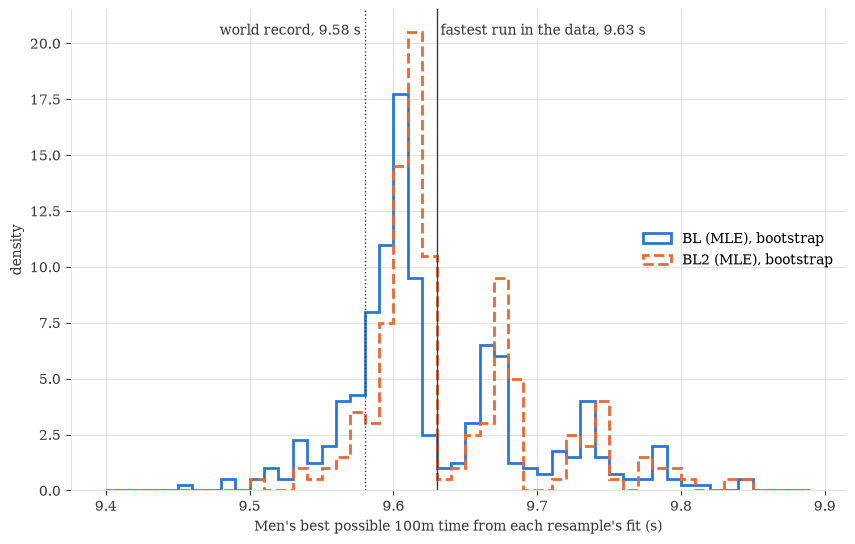

In [14]:
boot_M = {}
for fam in FAMILIES:
    u, ok, mx = bootstrap(fam, speeds_M, 'MLE', B[fam], seed=2012, flower=0)
    boot_M[fam] = u
    gap_s = 100 / mx - 100 / u            # how much faster than the resample's best
    f = fits['men', fam, 'MLE', None]
    print(f"{fam:<3} MLE: best possible {100 / f.upper:.2f} s; in the bootstrap the "
          f"bound is a median {np.median(gap_s):.2f} s (95% of resamples: "
          f"{np.percentile(gap_s, 2.5):.2f} to {np.percentile(gap_s, 97.5):.2f} s) "
          f"faster than the resample's fastest run ({ok.sum()}/{ok.size} identified)")

fig, ax = plt.subplots()
bins = np.arange(9.40, 9.90, 0.01)
for fam in FAMILIES:
    ax.hist(100 / boot_M[fam], bins=bins, histtype='step', density=True,
            label=f"{fam} (MLE), bootstrap", **STYLE[fam])
ax.axvline(100 / speeds_M.max(), color=INK, lw=1)
ax.annotate(' fastest run in the data, 9.63 s', (100 / speeds_M.max(), 0.97),
            xycoords=('data', 'axes fraction'), color=INK, va='top')
ax.axvline(9.58, color=INK, lw=1, ls=':')
ax.annotate('world record, 9.58 s ', (9.58, 0.97), xycoords=('data', 'axes fraction'),
            color=INK, va='top', ha='right')
ax.set_xlabel("Men's best possible 100m time from each resample's fit (s)")
ax.set_ylabel('density'); ax.legend(frameon=False, loc='center right')
plt.show()

The men's data put the best possible time **at or just past the record in the data**: a few hundredths of a second faster than the fastest run, in both families, and no more. Usain Bolt's world record of 9.58 s (Berlin, 2009, outside this sample, and still standing in 2026) is already faster than the data can see. The original's reading, that a fitted 9.44 s meant Bolt could have done better had he given 100%, does not hold up; the 9.44 s was where the optimizer stopped (Part 1). Another estimate of 9.44 s exists [in this article](https://www.bbc.com/future/article/20120712-will-we-ever-run-100m-in-9-secs), on other grounds.

For the women, Florence Griffith-Joyner's record of 10.49 s (1988, outside this sample, still standing in 2026) is slower than every estimate above. The estimates depend most on the choice of family and on fixing the mode, much less on the ECDF convention.

## 4. Does the bound show up in data we can control?

But aren't we assuming that the upper bound, which is outside the range of the sample data, is nonetheless inherent in the data?

Here is an example of a random sample of 10,000 fictional runners, each having 10 qualities with values ranging from 0 to 1. The sum of the runners' qualities therefore can range from 0 to 10. The perfect runner is a 10 and the perfectly worst runner is a 0. (Seeded now, so the numbers below are reproducible; the original was not.)

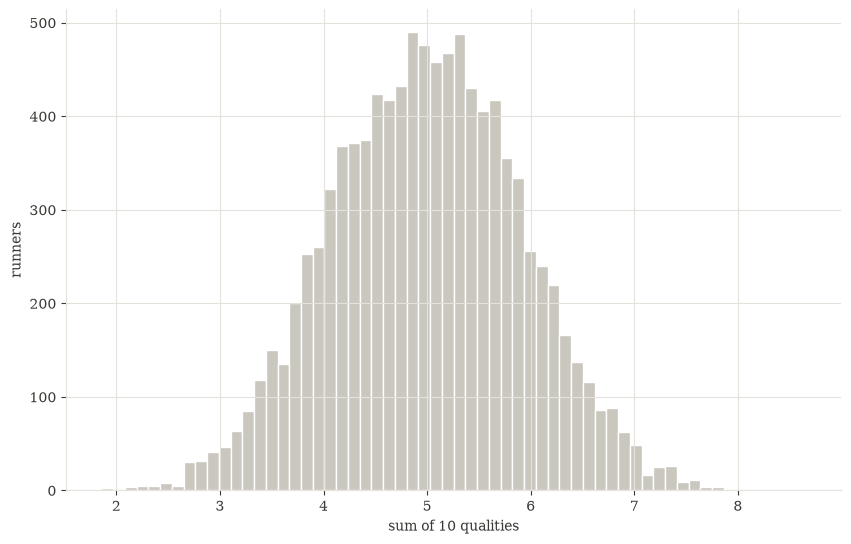

best runner in the sample: 8.66


In [15]:
def runners(seed, n=10_000):
    return np.random.default_rng(seed).random(size=(10, n)).sum(axis=0)

runner_sums = runners(seed=0)
fig, ax = plt.subplots()
ax.hist(runner_sums, bins=60, color=BARS, edgecolor='white', lw=1)
ax.set_xlabel('sum of 10 qualities'); ax.set_ylabel('runners')
plt.show()
print(f"best runner in the sample: {runner_sums.max():.2f}")

Say we don't know the value sum of the perfect runner, but we do of the worst (0). Let's estimate the perfect runner, first as the original did (BL, least squares, step ECDF, covariance interval), then with BL2:

In [16]:
runner_fits = {}
for fam in FAMILIES:
    f = fit(fam, runner_sums, 'LSQ', flower=0, ecdf='step')
    runner_fits[fam] = f
    se = f.stderr.upper
    print(f"{fam:<3} LSQ (step ECDF): best possible runner {f.upper:.2f}, "
          f"covariance interval (+-2 SE) [{f.upper - 2 * se:.2f}, {f.upper + 2 * se:.2f}]")

BL  LSQ (step ECDF): best possible runner 9.66, covariance interval (+-2 SE) [9.64, 9.69]


BL2 LSQ (step ECDF): best possible runner 9.42, covariance interval (+-2 SE) [9.41, 9.44]


The original printed 10.1 with an interval of [10.07, 10.13]. It was unseeded, so a different sample; seeded here, the fit is different again. That is the first sign the interval is far too narrow: the same procedure on a fresh sample of 10,000 lands well outside it.

Here we can measure the real uncertainty directly, because we can draw as many fresh samples as we like. Below, the same BL fit on many independent samples, against the covariance's standard error and against a bootstrap of the first sample:

In [17]:
ups, ses = [], []
for seed in range(REPEATS):
    f = fit('BL', runners(seed), 'LSQ', flower=0, ecdf='step')
    ups.append(f.upper); ses.append(f.stderr.upper)
ups, ses = np.array(ups), np.array(ses)
print(f"BL  over {REPEATS} independent samples: fitted bound mean {ups.mean():.2f}, "
      f"standard deviation {ups.std(ddof=1):.2f} (range {ups.min():.2f} to {ups.max():.2f})")
print(f"BL  covariance standard error, averaged over those samples: {ses.mean():.3f}, "
      f"{ups.std(ddof=1) / ses.mean():.0f}x too small")
print(f"BL  +-2 SE intervals that contain 10: {np.mean(np.abs(ups - 10) <= 2 * ses):.0%}")

boot_R = {}
for fam in FAMILIES:
    n_boot = B[fam] if fam == 'BL' else max(B['BL'] // 4, 2)     # BL2: slow at n = 10,000
    u, ok, _ = bootstrap(fam, runner_sums, 'LSQ', n_boot, seed=1, flower=0, ecdf='step')
    boot_R[fam] = u[ok]
    print(f"{fam:<3} bootstrap of the first sample: {ok.sum()}/{ok.size} resamples identify "
          f"the bound; their standard deviation {u[ok].std(ddof=1):.2f}, "
          f"95% [{np.percentile(u[ok], 2.5):.2f}, {np.percentile(u[ok], 97.5):.2f}]")

BL  over 100 independent samples: fitted bound mean 10.54, standard deviation 0.69 (range 9.36 to 12.63)
BL  covariance standard error, averaged over those samples: 0.024, 29x too small
BL  +-2 SE intervals that contain 10: 8%


BL  bootstrap of the first sample: 400/400 resamples identify the bound; their standard deviation 0.48, 95% [8.98, 10.88]


BL2 bootstrap of the first sample: 97/100 resamples identify the bound; their standard deviation 0.52, 95% [8.75, 10.78]


The covariance standard error is about 30 times smaller than the real spread of the estimate, and only about one interval in twelve contains the true 10. The bootstrap's spread (about 0.5) is roughly two-thirds of the real one (0.69): short, but the right order of magnitude, and computable from a single sample. A few BL2 resamples collapse onto their best runner, as the men's sprints did; the interval uses the resamples that identify the bound.

One more check: with unlimited data, what does the fit converge to? A sum of ten uniforms is not a bounded lognormal, so there is no reason for the best-fitting one to have its bound at exactly 10.

In [18]:
for fam, n in (('BL', 1_000_000), ('BL2', 200_000)):
    big = runners(seed=999, n=n)
    f_lsq = fit(fam, big, 'LSQ', flower=0, ecdf='step')
    f_mle = fit(fam, big, 'MLE', flower=0)
    print(f"{fam:<3} fitted to {n:,} runners: LSQ bound {f_lsq.upper:.2f}, "
          f"MLE bound {f_mle.upper:.2f}")
print(f"the perfect runner: 10; the best of the first sample: {runner_sums.max():.2f}")

BL  fitted to 1,000,000 runners: LSQ bound 10.49, MLE bound 11.13


BL2 fitted to 200,000 runners: LSQ bound 10.45, MLE bound 10.61
the perfect runner: 10; the best of the first sample: 8.66


With unlimited data the fits converge to between 10.45 and 11.13, depending on the family and the method, rather than to 10: the fitted bound is a property of the best-fitting bounded lognormal, not of the runners themselves.

These are still much closer to the theoretically perfect runner (with value sum = 10) than the best from the sample (8.66), as the original found. But the honest statement is wider than the original's: one sample of 10,000 puts the bound somewhere around 10, give or take about 0.7, and where exactly depends on the family and the method.

## Summary: what survives the move to the package

**Unchanged:**

- The women's least-squares fit with BL, the step ECDF and the mode fixed: 10.34 s, [10.25, 10.43] s from the covariance. The port reproduces the original exactly.
- BL's CDF itself: the package and the original code agree to 1e-14 at the parameters checked. The stable `lognorm_params` changes no number in this notebook.
- The fictional runners' qualitative point: the fitted bound is far above the best runner in the sample, around the true 10.

**Changed:**

- **Men.** The 9.44 s does not survive; it was an optimizer artifact. The data put the best possible time at or just past the record in the data (9.63 s). Since 0.2.1, `fit_bounds` reports the least-squares collapse instead of returning it.
- **Intervals.** For the fictional runners the covariance understates the real spread about 30-fold; use bootstrap refits. For a bound at the sample's maximum, even a bootstrap is not a confidence interval.
- **ECDF convention.** The midpoint default moves the women's estimate by 0.02–0.03 s.
- **MLE vs least squares, and BL vs BL2.** Each moves the women's estimate by up to a quarter of a second, more than the sampling noise. The MLE fits describe the data poorly (they are pulled wide by a few very slow runs), so least squares is the better guide here. BL and BL2 fit about equally well under least squares, but they are different distributions, so results are always reported with the family's name.
- **The women's fixed mode.** It is a modelling choice the result depends on; with the mode re-estimated in each resample the procedure is far less stable.